# 03 · Extracción de jugadas: piloto de detección temporal y revisión manual

Implementa **la Fase 1 del PDF**, consumiendo las salidas de los notebooks 01 y 02. Trabaja con **un video y una partida**. No entrena un modelo. No identifica automáticamente cartas ni posiciones todavía: esas fases dependen de validar primero los tiempos.

**No hay funciones de subida, exportación de pares VLM ni procesamiento masivo.** R2 solamente se consulta con `get_object`. Los CSV, JSON y plots son diagnósticos locales pendientes de revisión. Conservar el MP4 para volver a inspeccionarlo.

Orden: configuración → manifiestos → elección de partida → plots de cajas → marcar interior de barra → aprobar cajas → escaneo → candidatos → galerías → revisión. Ejecutar por secciones. Las aprobaciones son manuales y se invalidan al cambiar de video, partida, resolución o barra.

El PDF solicita caída de elixir ≤ −1.5 en ≤ 0.5 s, rotación/vaciado de slot, filtrado de selección y chat. Aquí las señales son **heurísticas ajustables**, no garantías de acierto. Se muestran también caídas menores (posible coste 1), señales débiles y cambios de slot sin caída para encontrar fallos.

In [1]:
pip install opencv-python-headless numpy pandas matplotlib requests boto3

Note: you may need to restart the kernel to use updated packages.


In [2]:

import os, json, re, hashlib
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

ROOT = Path('/kaggle/working/action_pilot') if Path('/kaggle').exists() else Path('data/action_pilot')
ROOT.mkdir(parents=True, exist_ok=True)

def get_config(key, default=None):
    try:
        from kaggle_secrets import UserSecretsClient
        value = UserSecretsClient().get_secret(key)
        if value:
            return value
    except Exception:
        pass
    return os.getenv(key, default)

# Entradas locales opcionales: evita R2 si ya descargaste los manifiestos.
SEGMENTS_FILE = None  # '/kaggle/input/.../segmented_matches.json'
LAYOUTS_FILE = None   # '/kaggle/input/.../ui_layouts.json'
LOCAL_VIDEO = None    # '/kaggle/input/.../<video_id>.mp4'; debe corresponder a VIDEO_ID
VIDEO_ID = None       # None = primer video con partidas y calibración; o indicar un ID concreto.
MATCH_POSITION = 0    # Posición en la lista de matches, desde cero; no es match_index.
SCAN_FPS = 10.0       # 0.1 s; puede aumentarse para combos rápidos.
MAX_SCAN_SECONDS = None  # None = partida completa; un valor limita SOLO el diagnóstico.
CDN_BASE = get_config('CDN_URL', 'https://cdn-cr.eddux.dev').rstrip('/')
R2_BUCKET = get_config('R2_BUCKET', 'cr-videos')

## 1. Leer metadatos y elegir una partida
No se consulta D1 ni se modifica infraestructura. Si faltan archivos locales, se utilizan los secretos de R2 de tu entorno. No imprimir credenciales.

En Kaggle, añade y **habilita para este notebook** los secretos `R2_ENDPOINT`, `R2_ACCESS_KEY` y `R2_SECRET_KEY` en **Add-ons → Secrets**; `R2_BUCKET` es opcional (por defecto `cr-videos`). Después vuelve a ejecutar desde la celda de configuración. Los secretos deben estar disponibles en el kernel que ejecuta el notebook: un `.env` local de VS Code no se transfiere al kernel remoto ni se carga automáticamente. Como alternativa, indica `SEGMENTS_FILE` y `LAYOUTS_FILE` con rutas a los JSON accesibles desde ese kernel.

`VIDEO_ID = None` selecciona automáticamente el primer video que tenga partidas y calibración. Si aparece el error antiguo «Elige VIDEO_ID en la configuración», guarda este notebook local y reinicia el kernel de Kaggle conectado; luego ejecuta de nuevo desde la celda de configuración para que la sesión use la versión actual.

In [3]:
def load_manifest(local_file, key):
    if local_file:
        return json.loads(Path(local_file).read_text(encoding='utf-8'))
    import boto3
    from botocore.config import Config
    values = {k: get_config(k) for k in ['R2_ENDPOINT', 'R2_ACCESS_KEY', 'R2_SECRET_KEY']}
    missing = [name for name, value in values.items() if not value or not value.strip()]
    if missing:
        raise RuntimeError(
            'No se pudo leer la configuración de R2: ' + ', '.join(missing) + '. '
            'En Kaggle, añade y habilita estos secretos para ESTE notebook en Add-ons → Secrets '
            'y vuelve a ejecutar desde la celda de configuración. '
            'Si usas un kernel remoto desde VS Code, las variables o el .env de tu PC '
            'no se transfieren al kernel. Como alternativa, define SEGMENTS_FILE y '
            'LAYOUTS_FILE con rutas a manifiestos accesibles desde el kernel.'
        )
    client = boto3.client('s3', endpoint_url=values['R2_ENDPOINT'],
                          aws_access_key_id=values['R2_ACCESS_KEY'],
                          aws_secret_access_key=values['R2_SECRET_KEY'],
                          config=Config(signature_version='s3v4', retries={'max_attempts': 3}))
    response = client.get_object(Bucket=R2_BUCKET, Key=key)
    try:
        return json.loads(response['Body'].read().decode('utf-8'))
    finally:
        response['Body'].close()

segments = load_manifest(SEGMENTS_FILE, 'metadata/segmented_matches.json')
layouts = load_manifest(LAYOUTS_FILE, 'metadata/ui_layouts.json')
videos = segments['videos']
ui_layouts = layouts['layouts']
choices = pd.DataFrame([
    {'video_id': vid, 'title': info.get('title', ''), 'partidas': len(info.get('matches', []))}
    for vid, info in videos.items() if vid in ui_layouts and info.get('matches')
])
display(choices)

,video_id,title,partidas
0,4Tt7nuuy-Bg,✨👀Partida de #clashroyale sin comentarios #Cla...,1
1,4YR1phwfrJU,✨👀Partida de #clashroyale sin comentarios #Cla...,1
2,4zwIliMVXV8,✨👀Partida de #clashroyale sin comentarios #Cla...,1
3,8Lls9S-ylSM,🥇Partida CLASH ROYALE sin comentar *BATALLA ÉP...,1
4,90HtKYg1jQE,✨👀Partida de #clashroyale sin comentarios #Cla...,1
5,IZrTA60YB7I,🏆3000+ 2.6 Hog top ladder,9
6,KcLv14GDAns,Partida de Clash Royale Arena 21 sin comentarios,1
7,LQdXz0DvY1c,✨👀Partida de #clashroyale sin comentarios #Cla...,1
8,QnFw3kiwOqo,✨👀Partida de #clashroyale sin comentarios #Cla...,1
9,Qy18H5V-nbE,✨👀Partida de #clashroyale sin comentarios #Cla...,1


In [4]:
if VIDEO_ID is None:
    VIDEO_ID = next((vid for vid, info in videos.items()
                     if vid in ui_layouts and info.get('matches')), None)
    if VIDEO_ID is None:
        raise RuntimeError('No hay videos con partidas y calibración en ambos manifiestos.')
    print(f'Video seleccionado automáticamente: {VIDEO_ID}')
if not re.fullmatch(r'[A-Za-z0-9_-]+', VIDEO_ID):
    raise ValueError('VIDEO_ID no válido.')
if VIDEO_ID not in videos or VIDEO_ID not in ui_layouts:
    raise ValueError('El video debe existir en ambos manifiestos.')
match_list = videos[VIDEO_ID]['matches']
display(pd.DataFrame(match_list))
if not 0 <= MATCH_POSITION < len(match_list):
    raise ValueError('MATCH_POSITION fuera de rango.')
match = match_list[MATCH_POSITION]
layout = ui_layouts[VIDEO_ID]
START, END = float(match['start_sec']), float(match['end_sec'])
if END <= START:
    raise ValueError('Intervalo de partida inválido.')
if not 10 <= SCAN_FPS <= 60:
    raise ValueError('Usa entre 10 y 60 muestras por segundo para este detector.')
RUN_DIR = ROOT / VIDEO_ID / f'partida_{MATCH_POSITION:02d}'
RUN_DIR.mkdir(parents=True, exist_ok=True)
print(f'Video {VIDEO_ID} | posición {MATCH_POSITION} | match_id {match.get("match_id")}')
print(f'Intervalo absoluto del MP4: {START:.2f}–{END:.2f} s; duración {END-START:.2f} s')

Video seleccionado automáticamente: 4Tt7nuuy-Bg


,match_id,match_index,start_sec,end_sec,duration_sec,start_clock,end_clock,in_overtime,youtube_url
0,4Tt7nuuy-Bg_p01,1,114,293,179,2:57,0:00,False,https://youtu.be/4Tt7nuuy-Bg?t=114


Video 4Tt7nuuy-Bg | posición 0 | match_id 4Tt7nuuy-Bg_p01
Intervalo absoluto del MP4: 114.00–293.00 s; duración 179.00 s


## 2. Descargar un MP4 y leer únicamente la partida seleccionada
La descarga contiene el video completo porque el CDN sirve un MP4. La selección temporal se hace al decodificar: se salta al inicio y se avanza secuencialmente hasta el final. No se crea un segundo MP4. Los tiempos de las detecciones son **segundos absolutos del video**, con una columna adicional relativa a la partida.

Descarga a `.part`, comprueba longitud si el servidor la informa y verifica que OpenCV abra el archivo antes de renombrarlo. Un archivo fallido no se reutiliza.

In [5]:
def validate_video(path):
    cap = cv2.VideoCapture(str(path))
    try:
        ok, frame = cap.read()
        if not cap.isOpened() or not ok or frame is None:
            raise RuntimeError('El MP4 no se puede decodificar.')
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if not np.isfinite(fps) or fps <= 0 or count <= 0:
            raise RuntimeError('FPS o duración del MP4 inválidos.')
        return fps, count, frame.shape[1], frame.shape[0]
    finally:
        cap.release()

def fetch_video(vid):
    target = ROOT / f'{vid}.mp4'
    if target.exists():
        validate_video(target)
        return target
    partial = target.with_suffix('.mp4.part')
    try:
        with requests.get(f'{CDN_BASE}/videos/{vid}.mp4', stream=True, timeout=(15, 120)) as response:
            response.raise_for_status()
            expected = response.headers.get('Content-Length')
            with partial.open('wb') as out:
                for chunk in response.iter_content(1024 * 1024):
                    if chunk:
                        out.write(chunk)
            if expected and not response.headers.get('Content-Encoding') and partial.stat().st_size != int(expected):
                raise RuntimeError('Descarga incompleta.')
        validate_video(partial)
        partial.replace(target)
    except Exception:
        partial.unlink(missing_ok=True)
        raise
    return target

VIDEO_PATH = Path(LOCAL_VIDEO) if LOCAL_VIDEO else fetch_video(VIDEO_ID)
SOURCE_FPS, FRAME_COUNT, WIDTH, HEIGHT = validate_video(VIDEO_PATH)
if SOURCE_FPS < SCAN_FPS:
    raise ValueError('El muestreo solicitado supera los FPS del video.')
if END > FRAME_COUNT / SOURCE_FPS + 1 / SOURCE_FPS:
    raise ValueError('El intervalo del manifiesto supera la duración del video; verificar el MP4 seleccionado.')
if list(layout['resolution']) != [WIDTH, HEIGHT]:
    raise ValueError('Resolución distinta a la calibración. No se escalan cajas silenciosamente.')

# Las cajas del notebook 02 son [x, y, ancho, alto], NO [x1, y1, x2, y2].
BOXES = layout['boxes_pixel']

def checked_box(box, shape):
    x, y, w, h = map(int, box)
    ih, iw = shape[:2]
    if w <= 0 or h <= 0 or x < 0 or y < 0 or x+w > iw or y+h > ih:
        raise ValueError(f'Caja fuera de imagen: {box}; imagen {iw}x{ih}')
    return x, y, w, h

def crop(frame, box):
    x, y, w, h = checked_box(box, frame.shape)
    return frame[y:y+h, x:x+w]

if len(BOXES['card_slots']) != 4:
    raise ValueError('Se esperan exactamente cuatro slots.')
for box in [BOXES['arena_box'], BOXES['elixir_bar_box'], *BOXES['card_slots']]:
    checked_box(box, (HEIGHT, WIDTH))

def read_frame(t):
    if not START <= t <= END:
        raise ValueError('El fotograma solicitado queda fuera de la partida.')
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    try:
        # Índice de frame: no usar tiempos relativos a la partida para acceder al MP4.
        index = min(int(round(t * SOURCE_FPS)), FRAME_COUNT-1)
        cap.set(cv2.CAP_PROP_POS_FRAMES, index)
        ok, frame = cap.read()
        if not ok:
            raise RuntimeError(f'No se pudo leer el frame en {t:.3f}s')
        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    finally:
        cap.release()

print(f'MP4 {WIDTH}×{HEIGHT}, {SOURCE_FPS:.3f} fps; se conserva localmente para revisión.')

MP4 590×1280, 59.720 fps; se conserva localmente para revisión.


## 3. Primer control manual: cajas y barra de elixir
La caja `elixir_bar_box` incluye número, gota y texto. Para medir el llenado hay que marcar **solo el interior horizontal de la barra**, desde el comienzo hasta su capacidad 10, sin la gota, bordes ni números. El plot muestra coordenadas absolutas del MP4. Copiar `[x, y, ancho, alto]` en la siguiente celda. No deducir el ancho total a partir del tramo magenta de una sola imagen.

Comprobar en varios instantes: arena completa, cuatro cartas (incluida elevación), interior de barra y ambas puntas. Si las cajas del notebook 02 fallan, corregir primero su calibración; aquí no se sobrescriben.

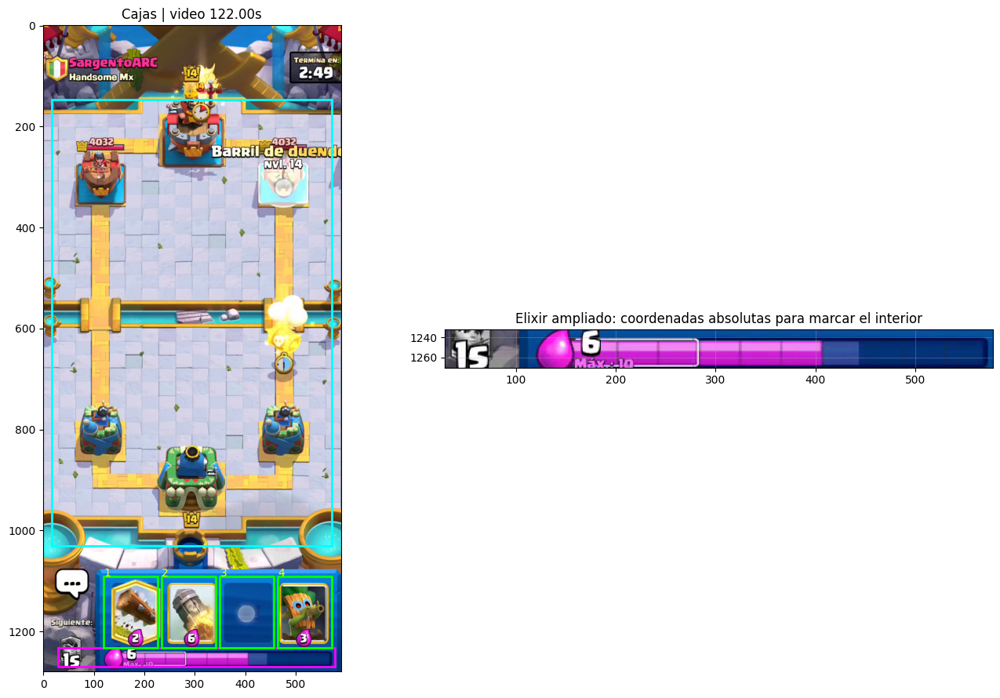

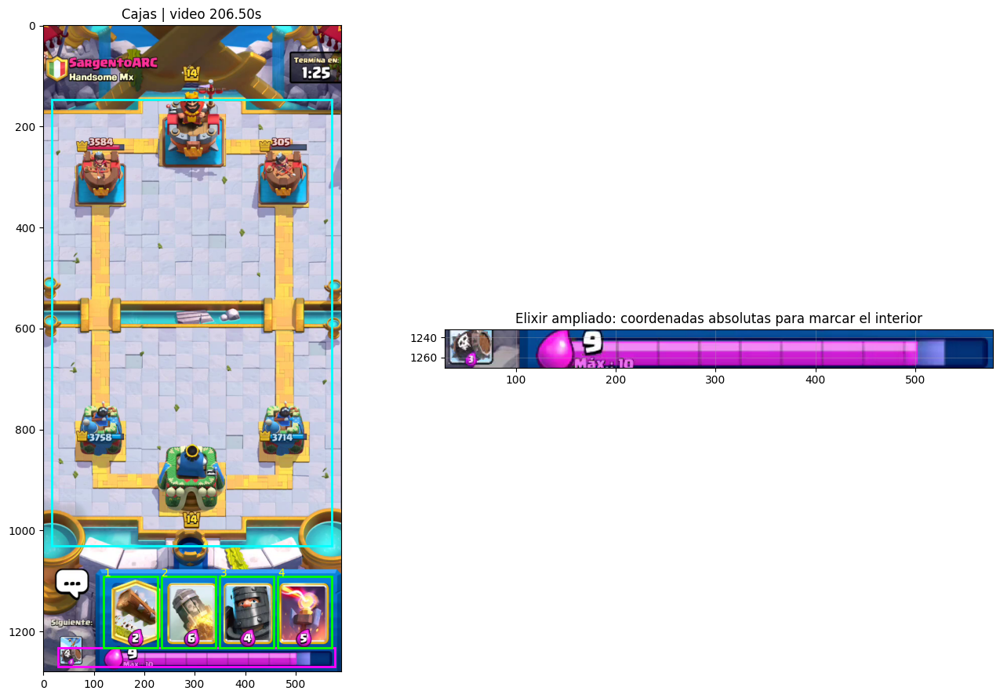

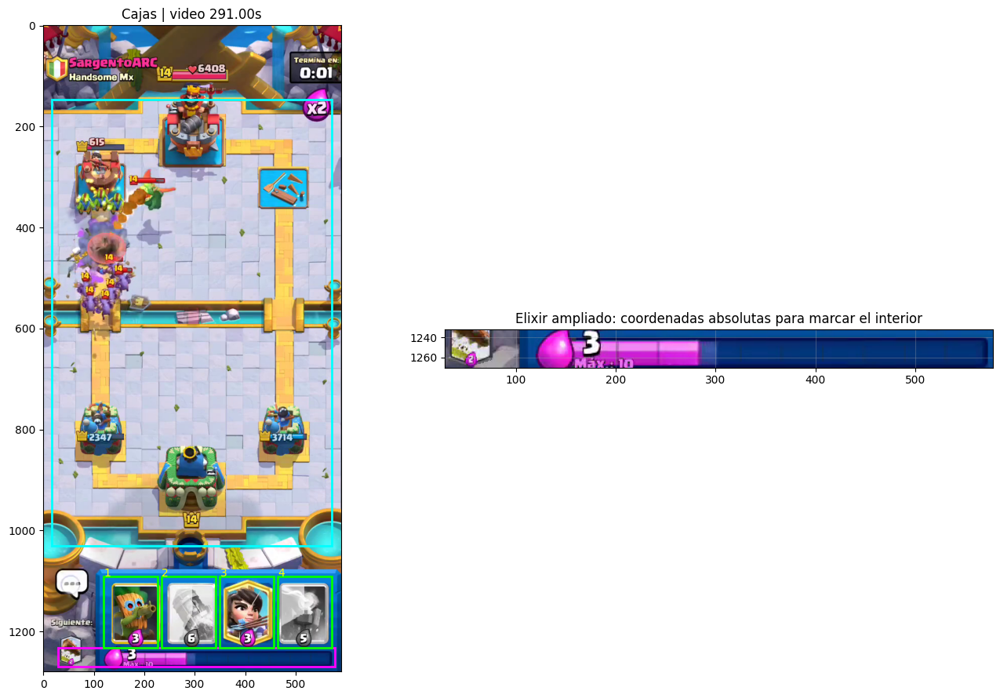

In [6]:
def show_layout(t):
    frame = read_frame(t)
    fig, axes = plt.subplots(1, 2, figsize=(14, 9))
    axes[0].imshow(frame)
    colors = {'arena_box': 'cyan', 'elixir_bar_box': 'magenta'}
    for key, color in colors.items():
        x,y,w,h = BOXES[key]
        axes[0].add_patch(plt.Rectangle((x,y), w,h, fill=False, edgecolor=color, linewidth=2))
    for i, box in enumerate(BOXES['card_slots'], 1):
        x,y,w,h = box
        axes[0].add_patch(plt.Rectangle((x,y),w,h,fill=False,edgecolor='lime',linewidth=2))
        axes[0].text(x,y,str(i),color='yellow')
    axes[0].set_title(f'Cajas | video {t:.2f}s')
    x,y,w,h = BOXES['elixir_bar_box']
    axes[1].imshow(crop(frame, [x,y,w,h]), extent=(x,x+w,y+h,y))
    axes[1].set_title('Elixir ampliado: coordenadas absolutas para marcar el interior')
    axes[1].grid(alpha=.3)
    plt.tight_layout()
    plt.show()

for t in np.linspace(START+min(8., (END-START)/4), END-min(2., (END-START)/4), 3):
    show_layout(float(t))

In [7]:
BAR_TRACK_XYWH = [160, 1257, 410, 5] 
LAYOUT_REVIEWED = True 
LAYOUT_APPROVAL_TOKEN = '895d5521b8d9'


MAGENTA_HSV_LOW = (125, 65, 60)
MAGENTA_HSV_HIGH = (179, 255, 255)
COLUMN_FILL_MIN = 0.35
CHAT_BLUE_MIN = 0.50
SLOT_CHANGE_MIN = 0.10
PRIMARY_DROP = 1.5
SMALL_DROP = 0.55
MIN_EVENT_SEPARATION = 0.20  # No usar 1.5s: borraría combos rápidos.

if BAR_TRACK_XYWH is None:
    raise RuntimeError('Marca el interior completo de la barra y vuelve a ejecutar esta celda.')
checked_box(BAR_TRACK_XYWH, (HEIGHT, WIDTH))
ex,ey,ew,eh = BOXES['elixir_bar_box']
bx,by,bw,bh = BAR_TRACK_XYWH
if not (ex <= bx and ey <= by and bx+bw <= ex+ew and by+bh <= ey+eh):
    raise ValueError('El interior de barra debe estar dentro de elixir_bar_box.')

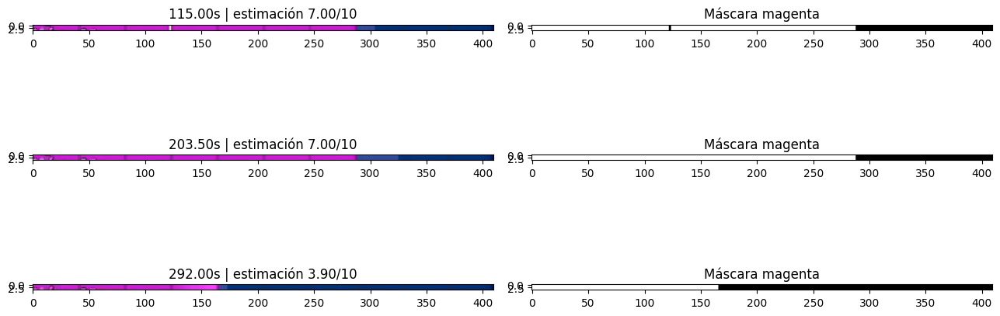

Inspecciona el ancho 0–10 y la máscara; después aprueba cajas con este token: 895d5521b8d9
Copia el token en LAYOUT_APPROVAL_TOKEN y cambia LAYOUT_REVIEWED a True.


In [8]:
def elixir_signal(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    mask = cv2.inRange(hsv, np.array(MAGENTA_HSV_LOW), np.array(MAGENTA_HSV_HIGH)) > 0
    # Mediana de filas por bloques de columnas: limita influencia de brillos y divisiones.
    columns = mask.mean(axis=0) >= COLUMN_FILL_MIN
    chunks = np.array_split(columns, min(100, len(columns)))
    fill = np.array([part.mean() >= .5 for part in chunks], dtype=float)
    # Conteo de ocupación, no extremo derecho: un píxel aislado no equivale a barra llena.
    return float(10 * fill.mean()), mask

def slot_descriptor(rgb):
    h,w = rgb.shape[:2]
    # Centro de ilustración; evita buena parte del borde blanco, coste y holgura superior.
    center = rgb[int(h*.22):max(int(h*.78),int(h*.22)+1), int(w*.12):max(int(w*.88),int(w*.12)+1)]
    return cv2.resize(center, (32,40), interpolation=cv2.INTER_AREA).astype(np.float32)/255

def chat_fraction(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    return float(cv2.inRange(hsv, np.array([90,70,35]), np.array([125,255,255])).mean()/255)

# Verificar primero el recorte y la máscara, ANTES de aprobar.
fig, axes = plt.subplots(3, 2, figsize=(13,6))
for row,t in enumerate(np.linspace(START+1, END-1, 3)):
    bar = crop(read_frame(float(t)), BAR_TRACK_XYWH)
    estimate,mask = elixir_signal(bar)
    axes[row,0].imshow(bar); axes[row,0].set_title(f'{t:.2f}s | estimación {estimate:.2f}/10')
    axes[row,1].imshow(mask,cmap='gray',vmin=0,vmax=1); axes[row,1].set_title('Máscara magenta')
plt.tight_layout(); plt.show()
def layout_token():
    payload = dict(video=VIDEO_ID, position=MATCH_POSITION, start=START, end=END,
                   boxes=BOXES, resolution=[WIDTH,HEIGHT], bar=BAR_TRACK_XYWH,
                   low=MAGENTA_HSV_LOW, high=MAGENTA_HSV_HIGH, column=COLUMN_FILL_MIN)
    return hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()[:12]

print('Inspecciona el ancho 0–10 y la máscara; después aprueba cajas con este token:',layout_token())
print('Copia el token en LAYOUT_APPROVAL_TOKEN y cambia LAYOUT_REVIEWED a True.')

### Contrastar la estimación con el número visible
Esta comparación conserva la caja completa de elixir, con el número del juego, y muestra por separado el interior de barra y su máscara. El rectángulo amarillo señala la región que se mide. La imagen ampliada de 5 píxeles usa interpolación por vecino más próximo; ampliarla no añade información.

Ejecutar primero con los tres tiempos de abajo. Tras el escaneo se seleccionarán también niveles bajos y altos. Escribir los números **leídos manualmente** en `ELIXIR_VISIBLE_BY_TIME`, usando los segundos impresos; dejar sin anotar los ilegibles o en transición. La barra estima llenado y el número muestra unidades enteras: la diferencia se usa como diagnóstico, sin asumir igualdad exacta ni aprobación automática. Estos plots no cambian el token ni los umbrales.


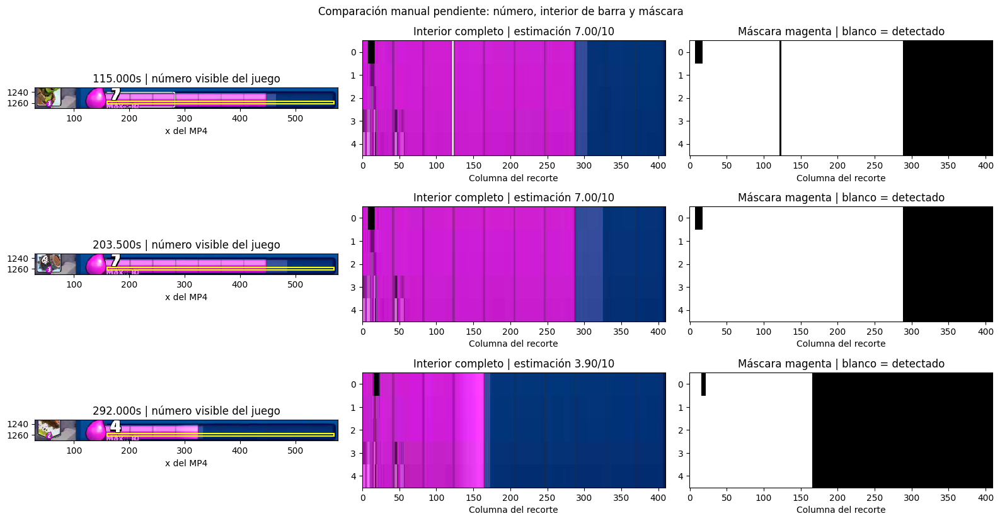

,timestamp_sec,elixir_estimate,visible_number_manual,estimate_minus_number
0,115.0,7.0,None,None
1,203.5,7.0,None,None
2,292.0,3.9,None,None


In [9]:
# Anotaciones manuales: {segundo absoluto mostrado: número visible de 0 a 10}.
# No rellenar con la estimación del detector ni con valores supuestos.
ELIXIR_VISIBLE_BY_TIME = {}

def plot_elixir_review(times, visible_by_time=None):
    times = [float(t) for t in times]
    if not times or len(times) > 12:
        raise ValueError('Revisar entre 1 y 12 instantes por plot.')
    visible_by_time = {} if visible_by_time is None else visible_by_time
    fig, axes = plt.subplots(len(times), 3, figsize=(16, 2.8 * len(times)), squeeze=False)
    records = []
    for row, t in enumerate(times):
        frame = read_frame(t)
        estimate, mask = elixir_signal(crop(frame, BAR_TRACK_XYWH))
        ex, ey, ew, eh = BOXES['elixir_bar_box']
        bx, by, bw, bh = BAR_TRACK_XYWH
        axes[row, 0].imshow(crop(frame, BOXES['elixir_bar_box']),
                            extent=(ex, ex+ew, ey+eh, ey), interpolation='nearest')
        axes[row, 0].add_patch(plt.Rectangle((bx, by), bw, bh, fill=False,
                                            edgecolor='yellow', linewidth=1.5))
        axes[row, 0].set_title(f'{t:.3f}s | número visible del juego')
        axes[row, 1].imshow(crop(frame, BAR_TRACK_XYWH), aspect='auto', interpolation='nearest')
        axes[row, 1].set_title(f'Interior completo | estimación {estimate:.2f}/10')
        axes[row, 2].imshow(mask, cmap='gray', vmin=0, vmax=1,
                            aspect='auto', interpolation='nearest')
        axes[row, 2].set_title('Máscara magenta | blanco = detectado')
        for ax in axes[row]:
            ax.set_xlabel('x del MP4' if ax is axes[row, 0] else 'Columna del recorte')
        # Clave de revisión redondeada como en el título, sin alterar el tiempo de lectura.
        visible = visible_by_time.get(round(t, 3))
        if visible is not None:
            visible = float(visible)
            if not np.isfinite(visible) or not 0 <= visible <= 10 or not visible.is_integer():
                raise ValueError('El número visible debe ser un entero de 0 a 10.')
        records.append({'timestamp_sec': round(t, 3), 'elixir_estimate': estimate,
                        'visible_number_manual': visible,
                        'estimate_minus_number': None if visible is None else estimate-visible})
    fig.suptitle('Comparación manual pendiente: número, interior de barra y máscara')
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    return pd.DataFrame(records)

ELIXIR_REVIEW_TIMES = [float(t) for t in np.linspace(START+1, END-1, 3)]
display(plot_elixir_review(ELIXIR_REVIEW_TIMES, ELIXIR_VISIBLE_BY_TIME))


## 4. Escaneo secuencial de la partida
Medición a 10 fps por defecto, sin guardar todos los frames en RAM. Se conservan descriptores pequeños de los cuatro slots para comparar antes/después. El detector de chat exige azul en los cuatro slots; es una heurística que también debe revisarse. No se interpreta el cierre del menú como jugada.

La señal visual de elixir es una estimación continua, no OCR ni coste exacto. No se impone una velocidad de regeneración única: regular, doble y otras fases pueden diferir.

In [10]:
if not LAYOUT_REVIEWED or LAYOUT_APPROVAL_TOKEN != layout_token():
    raise RuntimeError('Falta revisión manual o cambió el video/partida/barra. Revisa los plots y copia el nuevo token.')

config_snapshot = {
    'video_id': VIDEO_ID, 'match_position': MATCH_POSITION, 'start': START, 'end': END,
    'resolution': [WIDTH,HEIGHT], 'boxes': BOXES, 'bar_track': BAR_TRACK_XYWH,
    'scan_fps': SCAN_FPS, 'max_scan_seconds': MAX_SCAN_SECONDS,
    'hsv_low': MAGENTA_HSV_LOW, 'hsv_high': MAGENTA_HSV_HIGH,
    'column_fill_min': COLUMN_FILL_MIN, 'chat_blue_min': CHAT_BLUE_MIN,
    'slot_change_min': SLOT_CHANGE_MIN, 'primary_drop': PRIMARY_DROP,
    'small_drop': SMALL_DROP, 'min_event_separation': MIN_EVENT_SEPARATION,
}
RUN_HASH = hashlib.sha256(json.dumps(config_snapshot,sort_keys=True).encode()).hexdigest()[:12]
DIAG_DIR = RUN_DIR / RUN_HASH
DIAG_DIR.mkdir(exist_ok=True)

def scan_match():
    stop = END if MAX_SCAN_SECONDS is None else min(END, START+float(MAX_SCAN_SECONDS))
    if stop <= START:
        raise ValueError('MAX_SCAN_SECONDS debe ser positivo.')
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    times, levels, descriptors, blue = [], [], [], []
    first = int(np.ceil(START*SOURCE_FPS))
    next_sample = START
    try:
        cap.set(cv2.CAP_PROP_POS_FRAMES, first)
        index = first
        while index / SOURCE_FPS < stop:
            t = index / SOURCE_FPS
            ok = cap.grab()
            if not ok:
                raise RuntimeError(f'El video se interrumpió a {t:.2f}s; no aceptar diagnóstico incompleto.')
            if t+1e-8 >= next_sample:
                ok,bgr = cap.retrieve()
                if not ok:
                    raise RuntimeError(f'Falló decodificación a {t:.2f}s')
                rgb = cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
                cards = [crop(rgb,box) for box in BOXES['card_slots']]
                times.append(t)
                levels.append(elixir_signal(crop(rgb,BAR_TRACK_XYWH))[0])
                descriptors.append(np.stack([slot_descriptor(c) for c in cards]))
                blue.append([chat_fraction(c) for c in cards])
                next_sample += 1/SCAN_FPS
                if len(times) % int(SCAN_FPS*30) == 0:
                    print(f'Escaneados {t-START:.0f}/{stop-START:.0f}s de partida')
            index += 1
    finally:
        cap.release()
    if len(times) < 12:
        raise RuntimeError('Partida o tramo demasiado corto para comparación temporal.')
    return np.array(times), np.array(levels), np.array(descriptors), np.array(blue)

T, E, HAND, BLUE = scan_match()
CHAT = (BLUE >= CHAT_BLUE_MIN).all(axis=1)
print(f'{len(T)} muestras; {CHAT.sum()} con posible oclusión. No son etiquetas validadas.')

Escaneados 30/179s de partida
Escaneados 60/179s de partida
Escaneados 90/179s de partida
Escaneados 120/179s de partida
Escaneados 150/179s de partida
1790 muestras; 0 con posible oclusión. No son etiquetas validadas.


## 5. Candidatos: caída de elixir + cambio persistente de slot
Cada descenso local conserva un instante candidato. Se compara la mano anterior (≈ −0.8 s) con la posterior (≈ +0.5 s), además del cambio entre muestras. Dos caídas separadas no se agrupan por una ventana de 1.5 s. Eventos más rápidos que la resolución temporal o sin recuperación entre descensos pueden quedar fusionados: inspeccionar el plot.

`doble_señal` significa candidato con ambas señales; `revisar_caida` y `revisar_slot` señalan desacuerdos. Ninguno se aprueba automáticamente. Las muestras cercanas a oclusiones quedan visibles con marca de chat pero se excluyen de candidatos de jugada.

In [40]:
def detect_candidates(times, levels, hand, chat):
    n = len(times)
    step_change = np.zeros((n,4))
    step_change[1:] = np.abs(hand[1:] - hand[:-1]).mean(axis=(2,3,4))
    drops = np.zeros(n)
    persistent = np.zeros((n,4))
    occluded = np.zeros(n,dtype=bool)
    for i,t in enumerate(times):
        left = np.searchsorted(times,t-.5,side='left')
        # Mayor lectura anterior en ventana <=0.5 s: caída neta, sin proyectar coste.
        drops[i] = max(0., float(np.max(levels[left:i])-levels[i])) if i>left else 0.
        pre = np.searchsorted(times,t-.8,side='right')-1
        post = np.searchsorted(times,t+.5,side='left')
        if pre>=0 and post<n:
            persistent[i] = np.abs(hand[post]-hand[pre]).mean(axis=(1,2,3))
        a = max(0,np.searchsorted(times,t-.8))
        b = min(n,np.searchsorted(times,t+.5,side='right'))
        occluded[i] = chat[a:b].any()
    # Picos de caída en muestras consecutivas. El plateau conserva su primer máximo.
    local = np.zeros(n,dtype=bool)
    for i in range(1,n-1):
        local[i] = drops[i]>=SMALL_DROP and drops[i]>drops[i-1] and drops[i]>=drops[i+1]
    proposals=[]
    last=-np.inf
    for i in np.flatnonzero(local):
        if times[i]-last < MIN_EVENT_SEPARATION:
            continue
        last=times[i]
        strength = persistent[i]
        slot = int(np.argmax(strength))
        dual = strength[slot]>=SLOT_CHANGE_MIN
        proposals.append({'index':int(i),'timestamp_sec':float(times[i]),
                          'relative_sec':float(times[i]-START),'drop_estimate':float(drops[i]),
                          'slot_candidate':slot+1 if dual else None,
                          'slot_change':float(strength[slot]),
                          'signal':'doble_señal' if dual else 'revisar_caida',
                          'low_cost_candidate':bool(drops[i]<PRIMARY_DROP),
                          'occluded':bool(occluded[i]), 'review_status':'pending'})
    # Cambios de slot sin caída: muestra también falsos negativos potenciales y selecciones.
    last=-np.inf
    for i in range(1,n-1):
        strength=float(step_change[i].max())
        if strength<SLOT_CHANGE_MIN or times[i]-last<.5:
            continue
        if any(abs(p['timestamp_sec']-times[i])<=.5 for p in proposals):
            continue
        last=times[i]
        proposals.append({'index':i,'timestamp_sec':float(times[i]),
                          'relative_sec':float(times[i]-START),'drop_estimate':float(drops[i]),
                          'slot_candidate':int(np.argmax(step_change[i]))+1,'slot_change':strength,
                          'signal':'revisar_slot','low_cost_candidate':False,
                          'occluded':bool(occluded[i]),'review_status':'pending'})
    columns=['index','timestamp_sec','relative_sec','drop_estimate','slot_candidate',
             'slot_change','signal','low_cost_candidate','occluded','review_status']
    table=pd.DataFrame(proposals,columns=columns).sort_values('timestamp_sec').reset_index(drop=True)
    table.insert(0,'candidate_id',[f'{RUN_HASH}_{i:04d}' for i in range(len(table))])
    return table, drops, step_change, persistent, occluded

candidates,DROP,STEP_CHANGE,PERSISTENT,OCCLUDED = detect_candidates(T,E,HAND,CHAT)
display(candidates)
print('Candidatos totales:',len(candidates),'| con oclusión:',int(candidates.occluded.sum()))

,candidate_id,index,timestamp_sec,relative_sec,drop_estimate,slot_candidate,slot_change,signal,low_cost_candidate,occluded,review_status
0,594b216e2776_0000,10,115.003349,1.003349,0.0,3.0,0.253458,revisar_slot,False,False,pending
1,594b216e2776_0001,17,115.706631,1.706631,0.0,3.0,0.268233,revisar_slot,False,False,pending
2,594b216e2776_0002,22,116.208975,2.208975,0.0,1.0,0.177481,revisar_slot,False,False,pending
3,594b216e2776_0003,27,116.711319,2.711319,0.0,1.0,0.114951,revisar_slot,False,False,pending
4,594b216e2776_0004,37,117.716008,3.716008,0.0,3.0,0.364996,revisar_slot,False,False,pending
...,...,...,...,...,...,...,...,...,...,...,...
108,594b216e2776_0108,1731,287.106497,173.106497,2.5,1.0,0.366112,doble_señal,False,False,pending
109,594b216e2776_0109,1740,288.010717,174.010717,0.1,1.0,0.394741,revisar_slot,False,False,pending
110,594b216e2776_0110,1764,290.405224,176.405224,0.0,1.0,0.119917,revisar_slot,False,False,pending
111,594b216e2776_0111,1771,291.108506,177.108506,0.0,1.0,0.474881,revisar_slot,False,False,pending


Candidatos totales: 113 | con oclusión: 0


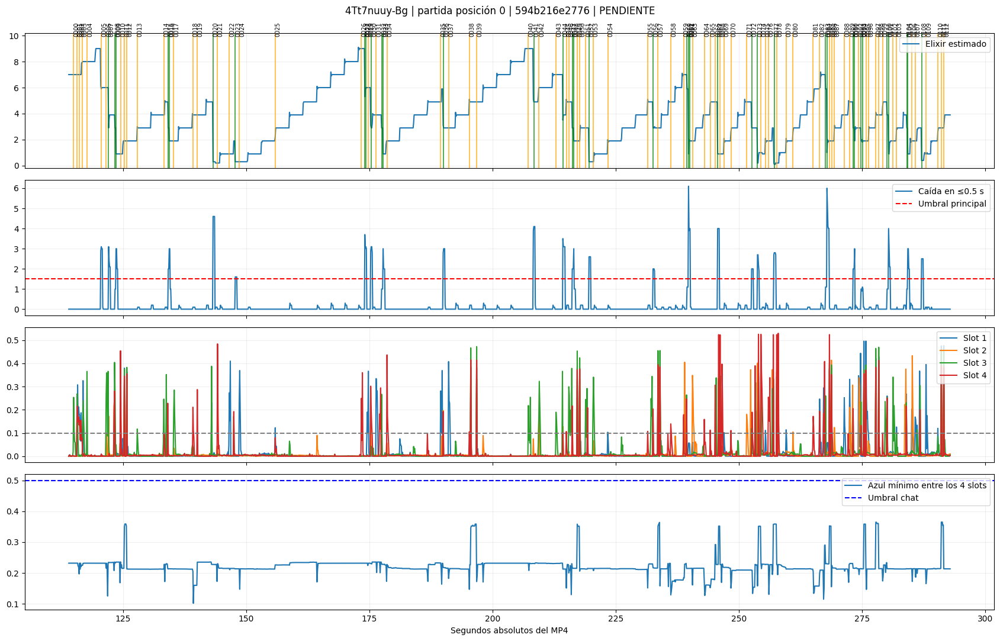

In [41]:
def plot_timeline(a=None,b=None):
    a = T[0] if a is None else a
    b = T[-1] if b is None else b
    mask=(T>=a)&(T<=b)
    fig,axes=plt.subplots(4,1,figsize=(17,11),sharex=True)
    axes[0].plot(T[mask],E[mask],label='Elixir estimado'); axes[0].set_ylim(-.2,10.2)
    axes[1].plot(T[mask],DROP[mask],label='Caída en ≤0.5 s')
    axes[1].axhline(PRIMARY_DROP,color='red',linestyle='--',label='Umbral principal')
    for slot in range(4):
        axes[2].plot(T[mask],STEP_CHANGE[mask,slot],label=f'Slot {slot+1}')
    axes[2].axhline(SLOT_CHANGE_MIN,color='gray',linestyle='--')
    axes[3].plot(T[mask],BLUE[mask].min(axis=1),label='Azul mínimo entre los 4 slots')
    axes[3].axhline(CHAT_BLUE_MIN,color='blue',linestyle='--',label='Umbral chat')
    for _,event in candidates.iterrows():
        if a<=event.timestamp_sec<=b:
            color='gray' if event.occluded else ('green' if event.signal=='doble_señal' else 'orange')
            axes[0].axvline(event.timestamp_sec,color=color,alpha=.65)
            axes[0].text(event.timestamp_sec,10.,event.candidate_id[-4:],rotation=90,fontsize=7)
    for ax in axes:
        ax.fill_between(T[mask],0,1,where=CHAT[mask],transform=ax.get_xaxis_transform(),color='blue',alpha=.10)
        ax.legend(loc='upper right'); ax.grid(alpha=.2)
    axes[-1].set_xlabel('Segundos absolutos del MP4')
    fig.suptitle(f'{VIDEO_ID} | partida posición {MATCH_POSITION} | {RUN_HASH} | PENDIENTE')
    plt.tight_layout()
    return fig

fig=plot_timeline()
fig.savefig(DIAG_DIR/'timeline.png',dpi=140,bbox_inches='tight')
plt.show()
# Para ampliar un combo o fallo: plot_timeline(START+20, START+28); plt.show()

### Revisar niveles bajos y altos después del escaneo
Se elige una muestra próxima a cada nivel solicitado **según la estimación todavía no validada**, sin afirmar que ese nivel real exista. Se eliminan tiempos repetidos y se muestra la distancia al nivel solicitado. Si el número está en transición, indicar otro instante en `ELIXIR_REVIEW_TIMES` de la comparación anterior. Anotar los números visibles allí y volver a ejecutar esta celda.


In [ ]:
ELIXIR_LEVEL_TARGETS = [0, 1, 2, 4, 7, 9, 10]
level_rows = []
level_times = []
for target in ELIXIR_LEVEL_TARGETS:
    idx = int(np.argmin(np.abs(E - target)))
    sec = float(T[idx])
    level_rows.append({'requested_level': target, 'timestamp_sec': round(sec, 3),
                       'scanned_estimate': float(E[idx]), 'distance_to_target': abs(float(E[idx])-target)})
    if sec not in level_times:
        level_times.append(sec)
display(pd.DataFrame(level_rows))
elixir_level_review = plot_elixir_review(level_times, ELIXIR_VISIBLE_BY_TIME)
display(elixir_level_review)
# Lecturas manuales pendientes: no se calculan métricas de exactitud automáticamente.


## 6. Galerías obligatorias: TODOS los candidatos, por páginas
Revisar la arena y los slots antes y después, incluyendo candidatos marcados con chat. Cambiar `PAGE` para recorrer la tabla completa; no revisar solo los primeros eventos. Los tiempos reales de lectura están cuantizados al FPS nativo.

El frame de decisión propuesto se sitúa a −0.7 s del candidato, pero **no está aprobado para entrenamiento** hasta corregir `t_drop` manualmente. En esta fase no se producen pares VLM.

Página 0; total páginas 23


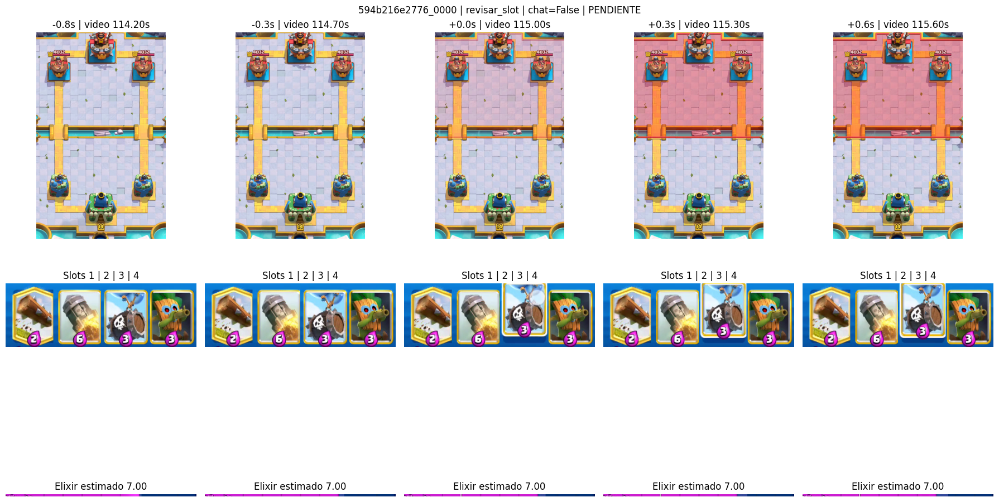

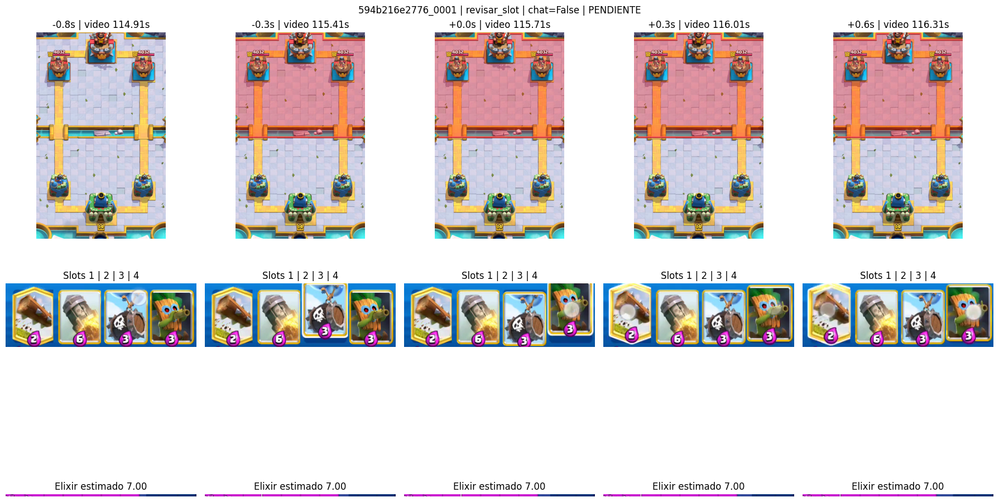

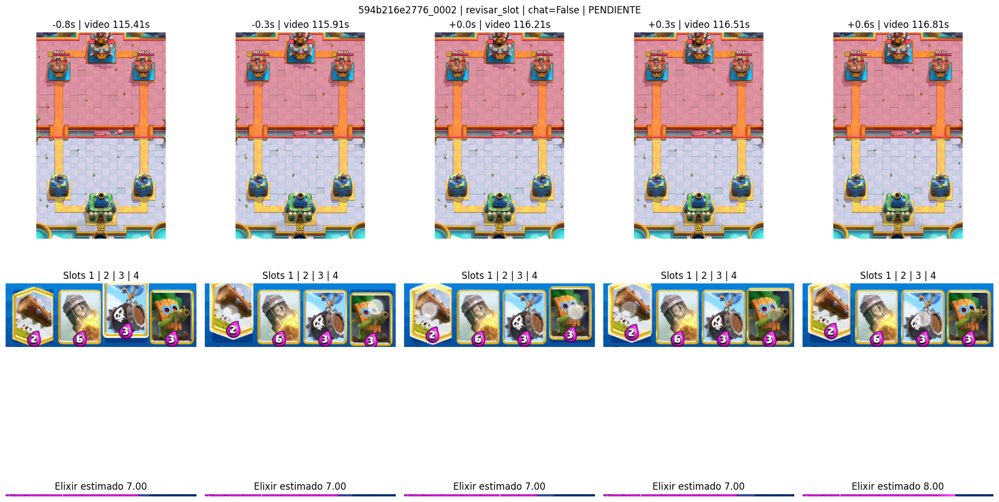

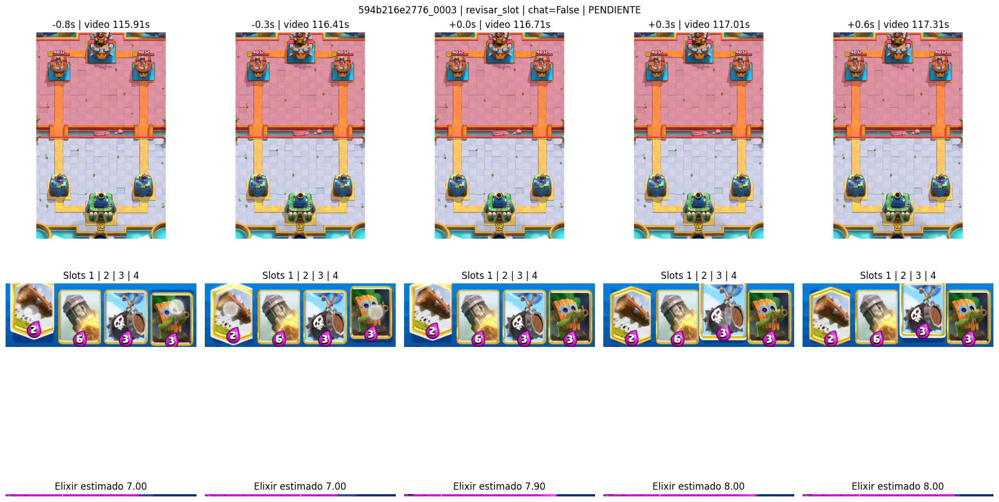

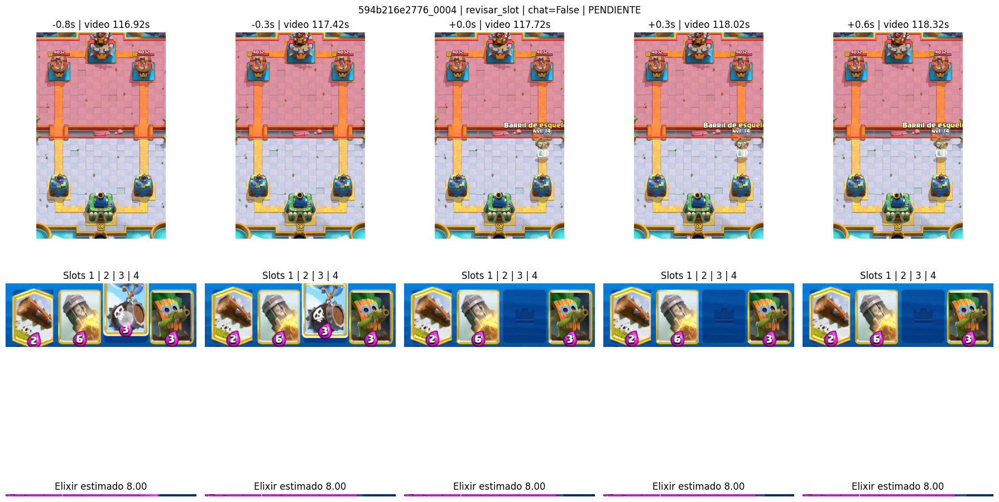

In [42]:
def plot_event(event):
    t=float(event['timestamp_sec'])
    offsets=[-.8,-.3,0.,.3,.6]
    fig,axes=plt.subplots(3,len(offsets),figsize=(18,11))
    for col,offset in enumerate(offsets):
        sec=t+offset
        if not START<=sec<=END:
            for row in range(3):
                axes[row,col].text(.1,.5,'Fuera de partida')
                axes[row,col].axis('off')
            continue
        frame=read_frame(sec)
        axes[0,col].imshow(crop(frame,BOXES['arena_box']))
        axes[0,col].set_title(f'{offset:+.1f}s | video {sec:.2f}s')
        # Los 4 slots, no solo el candidato: permite revisar combos y chat.
        cards=[cv2.resize(crop(frame,b),(96,128)) for b in BOXES['card_slots']]
        axes[1,col].imshow(np.concatenate(cards,axis=1))
        axes[1,col].set_title('Slots 1 | 2 | 3 | 4')
        bar=crop(frame,BAR_TRACK_XYWH)
        axes[2,col].imshow(bar)
        axes[2,col].set_title(f'Elixir estimado {elixir_signal(bar)[0]:.2f}')
        for row in range(3): axes[row,col].axis('off')
    fig.suptitle(f'{event["candidate_id"]} | {event["signal"]} | chat={event["occluded"]} | PENDIENTE')
    plt.tight_layout()
    return fig

PAGE=0
PAGE_SIZE=5
if PAGE < 0:
    raise ValueError('PAGE debe ser >= 0.')
print(f'Página {PAGE}; total páginas {max(1,int(np.ceil(len(candidates)/PAGE_SIZE)))}')
for _,event in candidates.iloc[PAGE*PAGE_SIZE:(PAGE+1)*PAGE_SIZE].iterrows():
    fig=plot_event(event)
    fig.savefig(DIAG_DIR/f'{event.candidate_id}.png',dpi=120,bbox_inches='tight')
    plt.show()
    plt.close(fig)

### Revisar primero doble señal, conservando las señales débiles
Las galerías anteriores y sus salidas se conservan como historial. Esta vista adicional filtra sin modificar `candidates`, sus identificadores ni los CSV. El recuento incluye siempre todas las categorías. `REVIEW_SIGNAL = None` muestra todas; `REVIEW_OCCLUDED = None` incluye tanto candidatos marcados con chat como sin él.

Cambiar `REVIEW_PAGE` desde cero para recorrer cada filtro. La tabla completa filtrada aparece sin truncamiento. Los candidatos siguen pendientes hasta registrarlos manualmente; filtrar no acepta ni rechaza eventos. Revisar también `revisar_caida`, `revisar_slot` y las ventanas de auditoría para buscar omisiones. Cero marcas de chat no demuestra ausencia de oclusiones.


In [ ]:
REVIEW_SIGNAL = 'doble_señal'  # None, 'doble_señal', 'revisar_caida' o 'revisar_slot'.
REVIEW_OCCLUDED = None        # None = todos; True = marcados con chat; False = sin marca.
REVIEW_PAGE = 0
REVIEW_PAGE_SIZE = 5


def filter_review_candidates(table, signal=None, occluded=None):
    if signal not in (None, 'doble_señal', 'revisar_caida', 'revisar_slot'):
        raise ValueError('REVIEW_SIGNAL no válido.')
    if occluded is not None and not isinstance(occluded, bool):
        raise ValueError('REVIEW_OCCLUDED debe ser None, True o False.')
    selected = table
    if signal is not None:
        selected = selected[selected.signal == signal]
    if occluded is not None:
        selected = selected[selected.occluded == occluded]
    return selected.sort_values('timestamp_sec').copy()


def plot_review_event(event):
    # Reutiliza arena y cuatro slots; amplía la caja completa para leer el número de elixir.
    fig = plot_event(event)
    for ax, offset in zip(fig.axes[-5:], [-.8, -.3, 0., .3, .6]):
        sec = float(event['timestamp_sec']) + offset
        if not START <= sec <= END:
            continue
        frame = read_frame(sec)
        ex, ey, ew, eh = BOXES['elixir_bar_box']
        bx, by, bw, bh = BAR_TRACK_XYWH
        ax.clear()
        ax.imshow(crop(frame, BOXES['elixir_bar_box']),
                  extent=(ex, ex+ew, ey+eh, ey), interpolation='nearest')
        ax.add_patch(plt.Rectangle((bx, by), bw, bh, fill=False,
                                   edgecolor='yellow', linewidth=1))
        estimate = elixir_signal(crop(frame, BAR_TRACK_XYWH))[0]
        ax.set_title(f'Número visible | estimación {estimate:.2f}')
        ax.axis('off')
    fig.tight_layout()
    return fig

if not isinstance(REVIEW_PAGE, int) or REVIEW_PAGE < 0:
    raise ValueError('REVIEW_PAGE debe ser un entero >= 0.')
if not isinstance(REVIEW_PAGE_SIZE, int) or not 1 <= REVIEW_PAGE_SIZE <= 12:
    raise ValueError('REVIEW_PAGE_SIZE debe ser un entero entre 1 y 12.')
print('Recuento completo por categoría y marca de oclusión:')
display(candidates.groupby(['signal', 'occluded']).size().rename('count').reset_index())
review_candidates = filter_review_candidates(candidates, REVIEW_SIGNAL, REVIEW_OCCLUDED)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(review_candidates)
review_pages = int(np.ceil(len(review_candidates) / REVIEW_PAGE_SIZE))
if review_pages == 0:
    print('Sin candidatos para este filtro.')
elif REVIEW_PAGE >= review_pages:
    raise ValueError(f'Página fuera de rango: usa 0–{review_pages-1}.')
else:
    print(f'Página {REVIEW_PAGE} de 0–{review_pages-1} | {len(review_candidates)} candidatos filtrados')
    for _, event in review_candidates.iloc[REVIEW_PAGE*REVIEW_PAGE_SIZE:(REVIEW_PAGE+1)*REVIEW_PAGE_SIZE].iterrows():
        fig = plot_review_event(event)
        fig.savefig(DIAG_DIR/f'{event.candidate_id}_full_elixir.png', dpi=120, bbox_inches='tight')
        plt.show()
        plt.close(fig)


## 7. Buscar jugadas omitidas y fallos de chat
Las galerías de candidatos no permiten encontrar todos los falsos negativos. Revisar también la partida completa por ventanas y registrar manualmente los eventos reales. Los puntos de abajo son una ayuda, no reemplazan la revisión completa del video.

Para cada instante: comprobar si hubo despliegue y elixir gastado, o solo selección de carta. Abrir ventanas densas cerca de combos, oclusiones y cambios de fase de elixir.

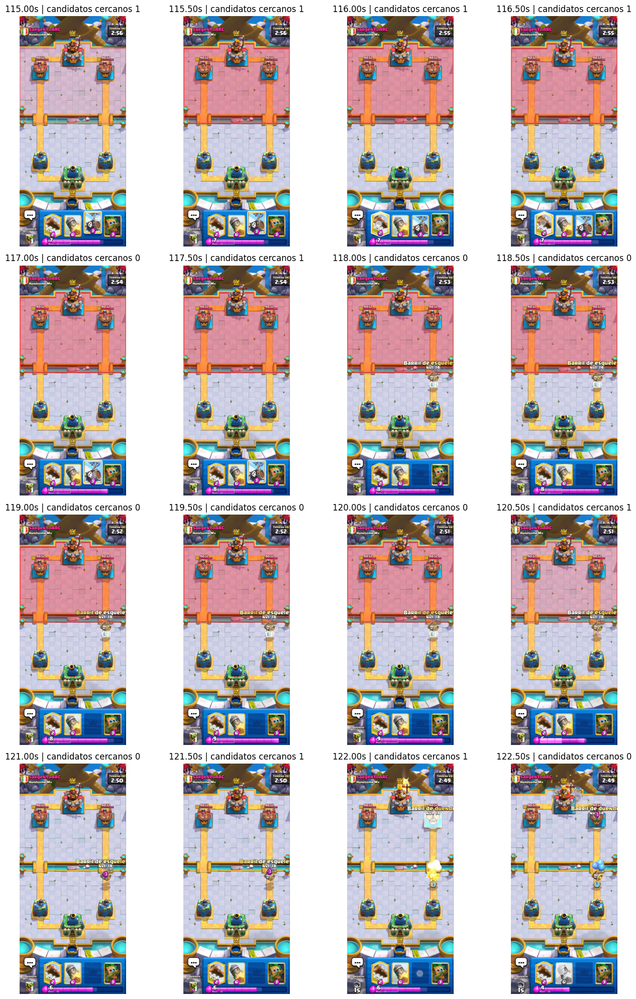

,timestamp_sec,chat_detectado


In [43]:
AUDIT_START = START + 1
AUDIT_END = min(END, AUDIT_START + 8)
AUDIT_STEP = .5

def plot_audit(a,b,step=.5):
    if not START<=a<b<=END or step<=0:
        raise ValueError('Ventana de auditoría inválida.')
    times=np.arange(a,b,step)
    # Paginación explícita para no agotar RAM en una partida larga.
    if len(times)>24:
        raise ValueError('Máximo 24 imágenes por plot; usa una ventana menor.')
    cols=4; rows=int(np.ceil(len(times)/cols))
    fig,axes=plt.subplots(rows,cols,figsize=(14,rows*5),squeeze=False)
    for ax,t in zip(axes.flat,times):
        ax.imshow(read_frame(float(t)))
        near=candidates[np.abs(candidates.timestamp_sec-t)<step/2]
        ax.set_title(f'{t:.2f}s | candidatos cercanos {len(near)}'); ax.axis('off')
    for ax in list(axes.flat)[len(times):]: ax.axis('off')
    plt.tight_layout(); plt.show(); plt.close(fig)

plot_audit(AUDIT_START,AUDIT_END,AUDIT_STEP)
# Cambiar AUDIT_START/AUDIT_END para recorrer toda la partida; reducir STEP para refinar t_drop.
# Posibles oclusiones, incluidas falsas alarmas:
chat_edges = np.flatnonzero(np.diff(CHAT.astype(int),prepend=0)!=0)
display(pd.DataFrame({'timestamp_sec':T[chat_edges], 'chat_detectado':CHAT[chat_edges]}))

## 8. Registro local de revisión y evaluación contra eventos manuales
El CSV incluye todos los candidatos con `pending`. Editar una copia: `accepted` si es jugada real, `rejected` si no, y completar tiempo corregido, slot y notas. No cambiar `pending` masivamente sin mirar imágenes.

Registrar **todas las jugadas reales** de la partida en `manual_truth.csv`, incluidas las omitidas por el detector. El evaluador usa emparejamiento temporal uno a uno para no contar dos candidatos como dos aciertos de una sola jugada. Las métricas solo describen el tramo anotado por la persona revisora. No se consideran etiquetas estratégicamente óptimas.

In [44]:
def atomic_json(path,data):
    temp=path.with_suffix(path.suffix+'.tmp')
    temp.write_text(json.dumps(data,indent=2,ensure_ascii=False),encoding='utf-8')
    temp.replace(path)

signals=pd.DataFrame({'timestamp_sec':T,'relative_sec':T-START,'elixir_estimate':E,
                      'drop_estimate':DROP,'chat_candidate':CHAT})
for slot in range(4):
    signals[f'slot_{slot+1}_change']=STEP_CHANGE[:,slot]
    signals[f'slot_{slot+1}_persistent']=PERSISTENT[:,slot]
    signals[f'slot_{slot+1}_blue']=BLUE[:,slot]
signals.to_csv(DIAG_DIR/'signals.csv',index=False)
candidates.to_csv(DIAG_DIR/'candidates.csv',index=False)
review_path=DIAG_DIR/'manual_review.csv'
if not review_path.exists():
    review=candidates.copy()
    for name in ['corrected_timestamp_sec','corrected_slot','notes']:
        review[name]=''
    review.to_csv(review_path,index=False)
truth_path=DIAG_DIR/'manual_truth.csv'
if not truth_path.exists():
    pd.DataFrame(columns=['timestamp_sec','hand_slot','notes']).to_csv(truth_path,index=False)
atomic_json(DIAG_DIR/'run_config.json',dict(config_snapshot,run_hash=RUN_HASH,
            state='pending_manual_review',source_video=str(VIDEO_PATH),
            source_fps=SOURCE_FPS,analysed_start=float(T[0]),analysed_end=float(T[-1])))
print('Diagnósticos locales:',DIAG_DIR.resolve())
print('La revisión existente no se sobrescribe. No se subió ningún resultado a R2.')

Diagnósticos locales: /kaggle/working/action_pilot/4Tt7nuuy-Bg/partida_00/594b216e2776
La revisión existente no se sobrescribe. No se subió ningún resultado a R2.


In [45]:
# Ejecutar DESPUÉS de anotar todos los eventos reales en la ventana indicada.
MANUAL_TRUTH_COMPLETE = False
ANNOTATED_START = float(T[0])
ANNOTATED_END = float(T[-1])
MATCH_TOLERANCE_SEC = .3

def evaluate_times(predicted, truth, tolerance):
    # Emparejamiento ordenado uno a uno con tolerancia; conserva eventos de combos.
    p=np.sort(np.asarray(predicted,dtype=float)); g=np.sort(np.asarray(truth,dtype=float))
    i=j=0; errors=[]
    while i<len(p) and j<len(g):
        if p[i]<g[j]-tolerance: i+=1
        elif p[i]>g[j]+tolerance: j+=1
        else:
            errors.append(float(p[i]-g[j])); i+=1; j+=1
    tp=len(errors); fp=len(p)-tp; fn=len(g)-tp
    return {'tp':tp,'fp':fp,'fn':fn,'precision':tp/(tp+fp) if tp+fp else None,
            'recall':tp/(tp+fn) if tp+fn else None,
            'mean_absolute_timing_error_sec':float(np.mean(np.abs(errors))) if errors else None}

if not MANUAL_TRUTH_COMPLETE:
    print('Métricas bloqueadas: falta completar la anotación manual de la ventana.')
else:
    if not T[0] <= ANNOTATED_START < ANNOTATED_END <= T[-1]:
        raise ValueError('La ventana anotada debe estar dentro del tramo analizado.')
    truth=pd.read_csv(truth_path)
    truth['timestamp_sec']=pd.to_numeric(truth.timestamp_sec,errors='raise')
    if not np.isfinite(truth.timestamp_sec).all():
        raise ValueError('Tiempos manuales inválidos.')
    if truth.timestamp_sec.duplicated().any():
        raise ValueError('Revisar tiempos manuales duplicados.')
    truth=truth[truth.timestamp_sec.between(ANNOTATED_START,ANNOTATED_END)]
    # Evaluar detector original, NO los tiempos corregidos manualmente.
    evaluated=candidates[(~candidates.occluded) & (candidates.signal=='doble_señal') &
                         candidates.timestamp_sec.between(ANNOTATED_START,ANNOTATED_END)]
    metrics=evaluate_times(evaluated.timestamp_sec,truth.timestamp_sec,MATCH_TOLERANCE_SEC)
    display(pd.DataFrame([metrics]))
    atomic_json(DIAG_DIR/'manual_evaluation.json',dict(metrics,run_hash=RUN_HASH,
                annotated_start=ANNOTATED_START,annotated_end=ANNOTATED_END,
                tolerance_sec=MATCH_TOLERANCE_SEC,state='manually_annotated_window'))

Métricas bloqueadas: falta completar la anotación manual de la ventana.


## Qué revisar antes de avanzar a la Fase 2 del PDF

- Cajas y máscara de barra correctas en todos los instantes inspeccionados.
- Recorrer **todas** las páginas de eventos, revisar toques sin jugar, combos y chat.
- Recorrer la partida para encontrar omisiones; registrar tiempos manuales y revisar métricas.
- Corregir tiempos sobre frames nativos antes de extraer entrada VLM. Comprobar visualmente que el frame actual, entre −0.8 y −0.5 s respecto al despliegue real, no revele la acción. Los otros frames serán −6, −4 y −2 s respecto a ese instante y no pueden salir de la partida.
- Repetir el piloto en dispositivos distintos; conservar los errores como casos de revisión.

**Fases posteriores del PDF (aún no implementadas):** banco de cartas/evoluciones y validación de coste; localización espacial y seis zonas con coordenadas normalizadas; candidatos de espera sin acciones durante ≥3 s y balance 80–85/15–20; JSONL con cuatro imágenes. La subida masiva y los checkpoints remotos se incorporarán únicamente después de la revisión manual y autorización del usuario. Este notebook no permite activarlos con un interruptor.

Las acciones observadas y la ausencia de jugadas no prueban por sí solas cuál era la mejor decisión estratégica. No usar diagnósticos pendientes como dataset final.